### Constraints
- Predict the age of the abalone with accuracy of +/- 3 years for 90% of predictions
- Limit Size & Memory

### Roles
- Tree Ensembles: Alia
- Knn: Yaqoub
- SVR: Alasdair
- Validation & Pipeline: Mrugaya
- Benchmarking & Testing: Raiyan

1. Imports and load data

In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import ai4_tools as ai4

from sklearn.model_selection import train_test_split, KFold, validation_curve, RandomizedSearchCV, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer, mean_absolute_error, mean_squared_error, root_mean_squared_error
from sklearn.inspection import permutation_importance
from sklearn.svm import SVR
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from scipy.stats import uniform, randint

# Load the Abalone dataset directly from the UCI repository
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/abalone/abalone.data"

column_names = [
    'Sex', 'Length', 'Diameter', 'Height',
    'Whole weight', 'Shucked weight', 'Viscera weight',
    'Shell weight', 'Rings'
]

df = pd.read_csv(url, header=None, names=column_names)
print("Data loaded successfully. Shape:", df.shape)

Data loaded successfully. Shape: (4177, 9)


2. Separate Features & Train/Test Split

In [65]:
# Separate features (X) and target (y -> Rings)
X = df.drop(columns=['Rings'])
y = df['Rings']

# Train-test split (using lowercase names to match your teammates' code blocks perfectly)
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training features shape: {x_train.shape}")
print(f"Test features shape: {x_test.shape}")

Training features shape: (3341, 8)
Test features shape: (836, 8)


3. Pipeline, Cross-Validation & Metric Skeleton - Mrugaya

In [66]:
# 1. PREPROCESSING PIPELINE
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), [0]),  # Encodes Sex (M, F, I)
        ('num', StandardScaler(), slice(1, 9))                 # Scales measurements
    ]
)

# 2. SHARED CROSS-VALIDATION PROTOCOL
shared_cv = KFold(n_splits=5, shuffle=True, random_state=42)

# 3. CUSTOM CONSTRAINT METRIC (+/- 3 years for 90% of cases)
def within_tolerance_score(y_true, y_pred):
    """
    Calculates the fraction of predictions that fall within
    +/- 3 units (years/rings) of the true value.
    """
    abs_errors = np.abs(y_true - y_pred)
    fraction_within = np.mean(abs_errors <= 3.0)
    return fraction_within

constraint_scorer = make_scorer(within_tolerance_score, greater_is_better=True)
print("Validation & Pipeline infrastructure loaded successfully")

Validation & Pipeline infrastructure loaded successfully


4. Model 1: Tree ensembles/HistGradientBoosting - Alia

In [67]:
hgb_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', HistGradientBoostingRegressor(random_state=42))
])

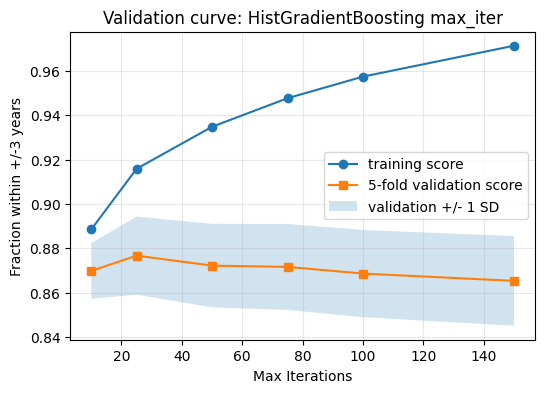

In [68]:
iter_values = [10, 25, 50, 75, 100, 150]
train_scores, validation_scores = validation_curve(
    hgb_pipeline,
    x_train,
    y_train,
    param_name="model__max_iter",
    param_range=iter_values,
    cv=shared_cv,
    scoring=constraint_scorer,
    n_jobs=-1,
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
validation_mean = validation_scores.mean(axis=1)
validation_std = validation_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(iter_values, train_mean, "o-", label="training score")
ax.plot(iter_values, validation_mean, "s-", label="5-fold validation score")
ax.fill_between(
    iter_values,
    validation_mean - validation_std,
    validation_mean + validation_std,
    alpha=0.2,
    label="validation +/- 1 SD",
)

ax.set_xlabel("Max Iterations")
ax.set_ylabel("Fraction within +/-3 years")
ax.set_title("Validation curve: HistGradientBoosting max_iter")
ax.legend()
ax.grid(alpha=0.3)
plt.show()


In [69]:
#Hyperparameters to be tuned
hgb_parameters = {
    'model__learning_rate': uniform(0.01, 1),
    'model__max_iter': randint(20, 110),
    'model__max_leaf_nodes': randint(10, 50),
    'model__min_samples_leaf': randint(1, 50),
    'model__l2_regularization': uniform(0, 10),
}

hgb_TUNE = "histgradboost"
start_hgb = time.time() # start timer for hyperparameter tuning

# Perform RandomizedSearchCV for HistGradientBoostingRegressor
hgb_random_search = RandomizedSearchCV(
    estimator=hgb_pipeline,
    param_distributions=hgb_parameters,
    n_iter=50,
    scoring=constraint_scorer,
    cv=shared_cv,
    n_jobs=-1,
    return_train_score=True,
)

# Begin hyperparameter tuning
hgb_random_search.fit(x_train, y_train)
end_hgb = time.time() # end timer for hyperparameter tuning

#Use best hyperparameter values to benchmark
hgb_metrics = ai4.benchmark(
    model=hgb_random_search.best_estimator_,
    X_train=x_train,
    y_train=y_train,
    X_test=x_test,
    y_test=y_test,
    scorer=within_tolerance_score,
    measure_memory=True,
    label="HistGradientBoostingRegressor (Tuned)",
)

#Model Performance Evaluation
table_hgb = ai4.ResultsTable()



table_hgb.add("HistGradientBoostingRegressor (Tuned)", hgb_metrics)
display(table_hgb.df())

# Store tuned model

if 'experiments' not in globals():
    experiments={}

#hgb_vector_number = random_search.best_estimator_.named_steps["HGB"].n_support_[0]
experiments[hgb_TUNE + ", tuned"] = hgb_random_search.best_estimator_

#Report best hyperparameters and time taken for tuning
print(f"Best score: {hgb_random_search.best_score_:.3f} years")
print(f"Total runtime for hyperparameter tuning: {end_hgb - start_hgb:.2f} seconds")

print("Best hyperparameters:")
for parameter, value in hgb_random_search.best_params_.items():
    print(f"{parameter}: {value}")


# MAE and RMSE for the best model
y_pred_hgb = hgb_random_search.predict(x_test)
print(f"MAE: {mean_absolute_error(y_test, y_pred_hgb):.3f} years")
print(f"RMSE: {root_mean_squared_error(y_test, y_pred_hgb):.3f} years")

,model,score,fit_s,predict_ms_per_1k,fit_s_best,predict_s,n_train,n_test,repeats,peak_mem_mb,mem_metric
0,HistGradientBoostingRegressor (Tuned),0.880383,0.550962,18.650023,0.389439,0.015591,3341,836,3,0.003906,host process RSS (peak minus baseline)


Best score: 0.876 years
Total runtime for hyperparameter tuning: 49.55 seconds
Best hyperparameters:
model__l2_regularization: 4.235289553114862
model__learning_rate: 0.026985701236934993
model__max_iter: 104
model__max_leaf_nodes: 46
model__min_samples_leaf: 8
MAE: 1.560 years
RMSE: 2.252 years


/tmp/ipykernel_467/1732435830.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


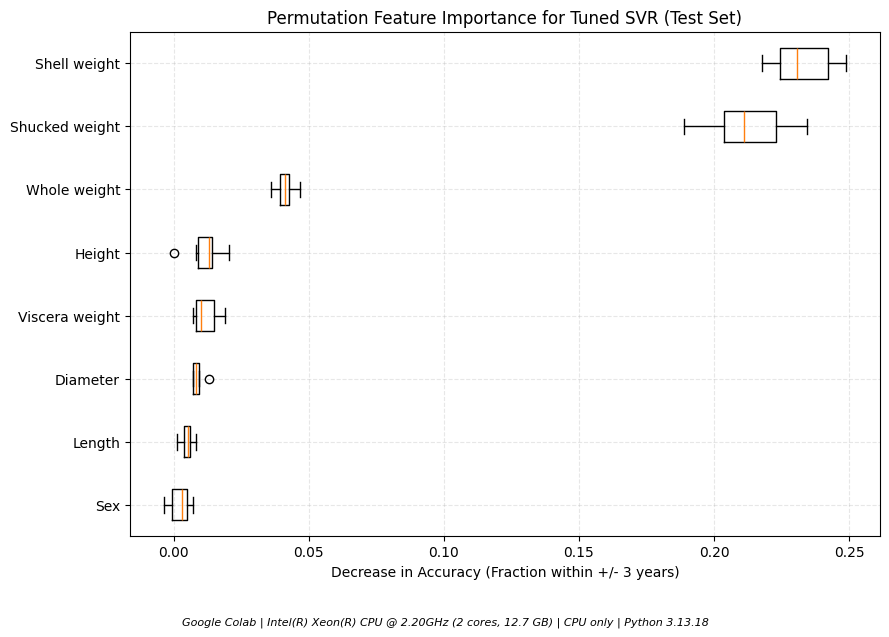

In [70]:
perm_importance = permutation_importance(
    hgb_random_search.best_estimator_,
    x_test,
    y_test,
    scoring=constraint_scorer,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

feature_names = x_test.columns.to_numpy()
sorted_idx = perm_importance.importances_mean.argsort()

#sorted_idx = perm_importance.importances_mean.argsort()

fig, ax = plt.subplots(figsize=(9, 6))
ax.boxplot(
    perm_importance.importances[sorted_idx].T,
    vert=False,
    labels=feature_names[sorted_idx]
)
ax.set_xlabel("Decrease in Accuracy (Fraction within +/- 3 years)")
ax.set_title("Permutation Feature Importance for Tuned SVR (Test Set)")
ax.grid(alpha=0.3, linestyle="--")

fig.text(0.5, -0.05, ai4.runtime_line(), ha="center", fontsize=8, style="italic")
plt.tight_layout()
plt.show()

In [71]:
best_hgb = hgb_random_search.best_estimator_
y_pred = best_hgb.predict(x_test)

final_hgb_export = {
    "Model Name": "Tuned HistGradientBoostingRegressor",
    "Test MAE": round(mean_absolute_error(y_test, y_pred), 3),
    "Test RMSE": round(root_mean_squared_error(y_test, y_pred), 3),
    "Custom Score (+/- 3 yrs)": round(hgb_metrics["score"], 3),
    "Training Time (s)": round(hgb_metrics["fit_s"], 3),
    "Prediction Time (ms/1k rows)": round(hgb_metrics["predict_ms_per_1k"], 3),
    "Memory Footprint (MB)": round(hgb_metrics["peak_mem_mb"], 3),
}

print("--- Final HGB Metrics for Group Compilation ---")
for key, val in final_hgb_export.items():
    print(f"{key}: {val}")

--- Final HGB Metrics for Group Compilation ---
Model Name: Tuned HistGradientBoostingRegressor
Test MAE: 1.56
Test RMSE: 2.252
Custom Score (+/- 3 yrs): 0.88
Training Time (s): 0.551
Prediction Time (ms/1k rows): 18.65
Memory Footprint (MB): 0.004


5. Model 2: SVR - Alasdair

In [72]:
RANDOM_STATE = 42
TEST_SIZE = 0.2
AGE_OFFSET = 1.5
TARGET = "rings"
CATEGORICAL_FEATURES = ["sex"]
NUMERIC_FEATURES = [
    "length",
    "diameter",
    "height",
    "whole_weight",
    "shucked_weight",
    "viscera_weight",
    "shell_weight",
]
def calculate_age(rings):
    """Convert the number of rings to age in years."""
    return rings + AGE_OFFSET

# Load the data from the CSV file and preprocess it
data = pd.read_csv("abalone.csv")
x = data.drop(columns=[TARGET])
y = data[TARGET]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('svr', SVR(kernel='rbf'))])

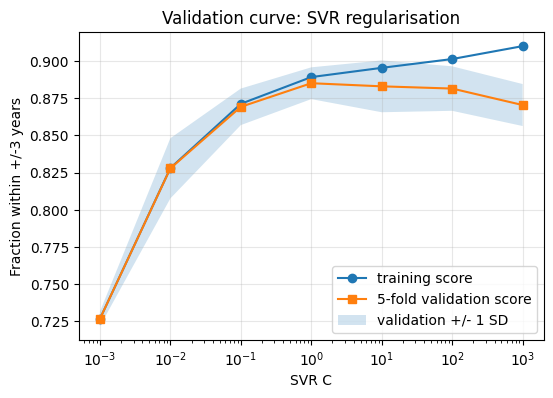

In [73]:
c_values = np.logspace(-3, 3, 7)
train_scores, validation_scores = validation_curve(
    pipeline,
    x_train,
    y_train,
    param_name="svr__C",
    param_range=c_values,
    cv=shared_cv,
    scoring=constraint_scorer,
    n_jobs=-1,
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
validation_mean = validation_scores.mean(axis=1)
validation_std = validation_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(c_values, train_mean, "o-", label="training score")
ax.plot(c_values, validation_mean, "s-", label="5-fold validation score")
ax.fill_between(
    c_values,
    validation_mean - validation_std,
    validation_mean + validation_std,
    alpha=0.2,
    label="validation +/- 1 SD",
)
ax.set_xscale("log")
ax.set_xlabel("SVR C")
ax.set_ylabel("Fraction within +/-3 years")
ax.set_title("Validation curve: SVR regularisation")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [74]:
parameter_grid = {
        "svr__C": np.logspace(1, 3, 4),
        "svr__gamma": np.logspace(-3, 1, 5),
        "svr__epsilon": [1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0],
    }
search = GridSearchCV(pipeline, parameter_grid, scoring={'constraint_scorer': constraint_scorer, 'neg_mean_squared_error': make_scorer(mean_squared_error, greater_is_better=False)}, refit='constraint_scorer', cv=shared_cv, n_jobs=-1, return_train_score=True)
search.fit(x_train, y_train)
svr_metrics = ai4.benchmark(model=search.best_estimator_, X_train=x_train, y_train=y_train, X_test=x_test, y_test=y_test, scorer=within_tolerance_score, label="Tuned SVR Pipeline", measure_memory=True)
table = ai4.ResultsTable()
table.add("SVR", svr_metrics)
display(table.df())
vector_number = search.best_estimator_.named_steps["svr"].n_support_[0]
print(f"Number of support vectors: {vector_number}")
print("Best hyperparameters:")
for parameter, value in search.best_params_.items():
    print(f"{parameter}: {value}")

,model,score,fit_s,predict_ms_per_1k,fit_s_best,predict_s,n_train,n_test,repeats,peak_mem_mb,mem_metric
0,SVR,0.87799,0.570143,68.7656,0.556001,0.057488,3341,836,3,12.339844,host process RSS (peak minus baseline)


Number of support vectors: 1176
Best hyperparameters:
svr__C: 1000.0
svr__epsilon: 1.5
svr__gamma: 0.01


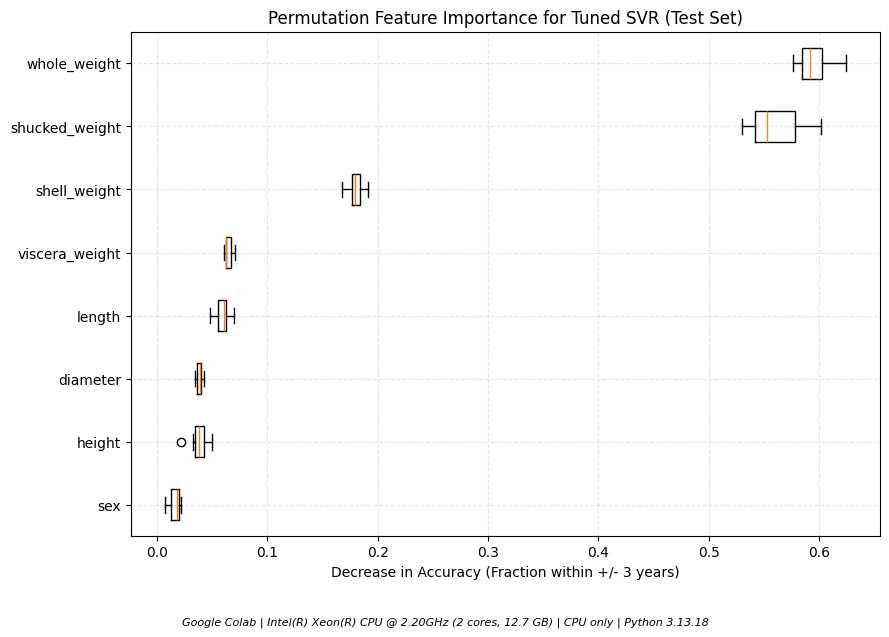

In [75]:
from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(
    search.best_estimator_,
    x_test,
    y_test,
    scoring=constraint_scorer,
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

feature_names = x_test.columns.to_numpy()
sorted_idx = perm_importance.importances_mean.argsort()

sorted_idx = perm_importance.importances_mean.argsort()

fig, ax = plt.subplots(figsize=(9, 6))
ax.boxplot(
    perm_importance.importances[sorted_idx].T,
    vert=False,
    tick_labels=feature_names[sorted_idx]
)
ax.set_xlabel("Decrease in Accuracy (Fraction within +/- 3 years)")
ax.set_title("Permutation Feature Importance for Tuned SVR (Test Set)")
ax.grid(alpha=0.3, linestyle="--")

fig.text(0.5, -0.05, ai4.runtime_line(), ha="center", fontsize=8, style="italic")
plt.tight_layout()
plt.show()

In [76]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

best_svr = search.best_estimator_
y_pred = best_svr.predict(x_test)

final_svr_export = {
    "Model Name": "Tuned SVR",
    "Test MAE": round(mean_absolute_error(y_test, y_pred), 3),
    "Test RMSE": round(root_mean_squared_error(y_test, y_pred), 3),
    "Custom Score (+/- 3 yrs)": round(svr_metrics["score"], 3),
    "Training Time (s)": round(svr_metrics["fit_s"], 3),
    "Prediction Time (ms/1k rows)": round(svr_metrics["predict_ms_per_1k"], 3),
    "Memory Footprint (MB)": round(svr_metrics["peak_mem_mb"], 3),
    "Support Vector Count": best_svr.named_steps['svr'].n_support_[0]
}

print("--- Final SVR Metrics for Group Compilation ---")
for key, val in final_svr_export.items():
    print(f"{key}: {val}")

--- Final SVR Metrics for Group Compilation ---
Model Name: Tuned SVR
Test MAE: 1.508
Test RMSE: 2.186
Custom Score (+/- 3 yrs): 0.878
Training Time (s): 0.57
Prediction Time (ms/1k rows): 68.766
Memory Footprint (MB): 12.34
Support Vector Count: 1176


6. Model 3: Knn - Yaqoub

In [77]:
from sklearn.model_selection import train_test_split

# Split your data (using capital X and y from your data loading cell)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

Training set shape: (3341, 8)
Test set shape: (836, 8)


In [78]:
knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', KNeighborsRegressor())
])

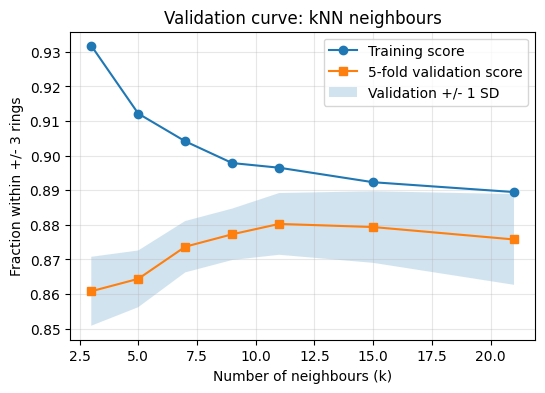

In [79]:
from sklearn.model_selection import validation_curve

neighbors = [3, 5, 7, 9, 11, 15, 21]

train_scores, val_scores = validation_curve(
    knn_pipeline,
    x_train,
    y_train,
    param_name="regressor__n_neighbors",
    param_range=neighbors,
    cv=shared_cv,
    scoring=constraint_scorer,
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(neighbors, train_mean, "o-",
        label="Training score")

ax.plot(neighbors, val_mean, "s-",
        label="5-fold validation score")

ax.fill_between(
    neighbors,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.2,
    label="Validation +/- 1 SD"
)

ax.set_xlabel("Number of neighbours (k)")
ax.set_ylabel("Fraction within +/- 3 rings")
ax.set_title("Validation curve: kNN neighbours")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

In [80]:

from sklearn.model_selection import GridSearchCV


param_grid = {
    'regressor__n_neighbors': [3, 5, 7, 9, 11, 15, 21],
    'regressor__weights': ['uniform', 'distance']
}


grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=shared_cv,
    scoring={
        'within_3': constraint_scorer,
        'mae': 'neg_mean_absolute_error'
    },
    refit='within_3',
    return_train_score=True,
    n_jobs=-1
)

with ai4.timed("kNN Hyperparameter Tuning"):
    grid_search.fit(x_train, y_train)

best_index = grid_search.best_index_
best_knn = grid_search.best_estimator_

best_cv_score = grid_search.best_score_ * 100
best_cv_mae = -grid_search.cv_results_[
    'mean_test_mae'
][best_index]

print("Best parameters:", grid_search.best_params_)
print(f"Best CV within +/- 3 rings: {best_cv_score:.2f}%")
print(f"CV MAE for selected model: {best_cv_mae:.4f}")

kNN Hyperparameter Tuning: 4.5472 s
Best parameters: {'regressor__n_neighbors': 11, 'regressor__weights': 'uniform'}
Best CV within +/- 3 rings: 88.03%
CV MAE for selected model: 1.5635


In [81]:
best_knn = grid_search.best_estimator_

knn_metrics = ai4.benchmark(
    model=best_knn,
    X_train=x_train,
    y_train=y_train,
    X_test=x_train,
    y_test=y_train,
    scorer=within_tolerance_score,
    measure_memory=True,
    label="Tuned kNN"
)

table_knn = ai4.ResultsTable()
table_knn.add("Tuned kNN", knn_metrics)
display(table_knn.df())

,model,score,fit_s,predict_ms_per_1k,fit_s_best,predict_s,n_train,n_test,repeats,peak_mem_mb,mem_metric
0,Tuned kNN,0.897935,0.011398,19.694417,0.011108,0.065799,3341,3341,3,0.003906,host process RSS (peak minus baseline)


In [82]:
if 'experiments' not in globals():
    experiments = {}

experiments['kNN_tuned'] = best_knn

knn_summary = {
    'Model': 'Tuned kNN',
    'Neighbours': grid_search.best_params_[
        'regressor__n_neighbors'
    ],
    'Weights': grid_search.best_params_[
        'regressor__weights'
    ],
    'CV within +/- 3 (%)': round(best_cv_score, 2),
    'CV MAE': round(best_cv_mae, 4),
    'Training time (s)': round(knn_metrics['fit_s'], 4),
    'Prediction time (ms/1k)': round(
        knn_metrics['predict_ms_per_1k'], 3
    ),
    'Peak memory increase (MB)': round(
        knn_metrics['peak_mem_mb'], 4
    )
}

display(pd.DataFrame([knn_summary]))

,Model,Neighbours,Weights,CV within +/- 3 (%),CV MAE,Training time (s),Prediction time (ms/1k),Peak memory increase (MB)
0,Tuned kNN,11,uniform,88.03,1.5635,0.0114,19.694,0.0039


7. Final metrics comparison table - Mrugaya

In [83]:
import pandas as pd

# Compile the final metrics table using the pre-computed metrics from each model's section
metrics_list = [
    {
        "Model": "HistGradientBoosting (Tuned)",
        "MAE": final_hgb_export["Test MAE"],
        "RMSE": final_hgb_export["Test RMSE"],
        "Custom Score (+/- 3 yrs)": final_hgb_export["Custom Score (+/- 3 yrs)"],
        "Training Time (s)": final_hgb_export["Training Time (s)"],
    },
    {
        "Model": "SVR (Tuned)",
        "MAE": final_svr_export["Test MAE"],
        "RMSE": final_svr_export["Test RMSE"],
        "Custom Score (+/- 3 yrs)": final_svr_export["Custom Score (+/- 3 yrs)"],
        "Training Time (s)": final_svr_export["Training Time (s)"],
    },
    {
        "Model": "kNN (Tuned)",
        "MAE": round(best_cv_mae, 3),
        "RMSE": round(knn_metrics["rmse"], 3) if "rmse" in knn_metrics else "N/A",
        "Custom Score (+/- 3 yrs)": round(knn_metrics["score"], 3),
        "Training Time (s)": round(knn_metrics["fit_s"], 3),
    },
]

# Display the final comparison table
comparison_df = pd.DataFrame(metrics_list)
display(comparison_df)

,Model,MAE,RMSE,Custom Score (+/- 3 yrs),Training Time (s)
0,HistGradientBoosting (Tuned),1.560,2.252,0.880,0.551
1,SVR (Tuned),1.508,2.186,0.878,0.570
2,kNN (Tuned),1.564,N/A,0.898,0.011


8. Benchmarking and testing - Raiyan

In [84]:
print("Training rows:", len(x_train))
for name in ("best_knn", "best_svr", "best_hgb", "shared_cv"):
    print(name, "ready" if name in globals() else "missing")

Training rows: 3341
best_knn ready
best_svr ready
best_hgb ready
shared_cv ready


In [85]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline

linear_ref_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression()),
])

models = {
    "Linear Regression": linear_ref_pipe,
    "Tuned kNN": best_knn,
    "Tuned SVR": best_svr,
    "Tuned HGB": best_hgb,
}

timing_batch = x_train.iloc[:1000] # Time every model on the same 1,000 rows
rows = []

for name, model in models.items():
  # Compare all four models using the same five validation folds.
    scores = cross_validate(
        model,
        x_train,
        y_train,
        cv=shared_cv,
        scoring={
            "within_3": constraint_scorer,
            "mae": "neg_mean_absolute_error",
        },
        return_train_score=True,
    )

    timing = ai4.benchmark(
        model=model,
        X_train=x_train,
        y_train=y_train,
        X_test=timing_batch,
        repeats=3,
        label=name,
    )

    rows.append({ # Convert the within-3 score to a percentage and report MAE as a positive value.
        "Model": name,
        "Training within ±3 (%)": 100 * scores["train_within_3"].mean(),
        "Validation within ±3 (%)": 100 * scores["test_within_3"].mean(),
        "Validation MAE": -scores["test_mae"].mean(),
        "Fit time (s)": timing["fit_s"],
        "Prediction time (ms/1,000 rows)": timing["predict_ms_per_1k"],
    })

benchmark_results = pd.DataFrame(rows)
display(benchmark_results.round(3))

,Model,Training within ±3 (%),Validation within ±3 (%),Validation MAE,Fit time (s),"Prediction time (ms/1,000 rows)"
0,Linear Regression,87.594,87.459,1.589,0.009,4.493
1,Tuned kNN,89.651,88.028,1.564,0.011,35.546
2,Tuned SVR,89.659,88.865,1.484,0.563,68.958
3,Tuned HGB,93.093,87.638,1.513,0.396,20.892


In [86]:
print(ai4.runtime_line())
benchmark_results.to_csv("abalone_benchmark_results.csv", index=False)

Google Colab | Intel(R) Xeon(R) CPU @ 2.20GHz (2 cores, 12.7 GB) | CPU only | Python 3.13.18


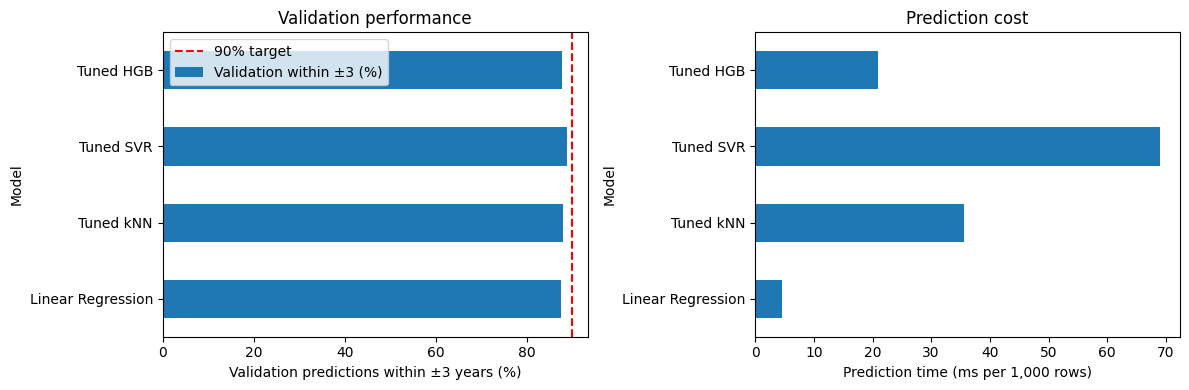

In [87]:
import matplotlib.pyplot as plt

results = benchmark_results.set_index("Model")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

results["Validation within ±3 (%)"].plot.barh(ax=ax1)
ax1.axvline(90, color="red", linestyle="--", label="90% target")
ax1.set_xlabel("Validation predictions within ±3 years (%)")
ax1.set_title("Validation performance")
ax1.legend()

results["Prediction time (ms/1,000 rows)"].plot.barh(ax=ax2)
ax2.set_xlabel("Prediction time (ms per 1,000 rows)")
ax2.set_title("Prediction cost")

fig.tight_layout()
plt.show()